Rows before filtering: 8807
Movie rows: 6131
Rows removed for null/NaN values: 444
Complete movie rows: 5687
Final feature rows: 5687
Final feature count: 153


TfidfVectorizer(max_df=0.85, min_df=3, ngram_range=(1, 2), stop_words='english',
                sublinear_tf=True)
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 82697 stored elements and shape (6131, 7979)>


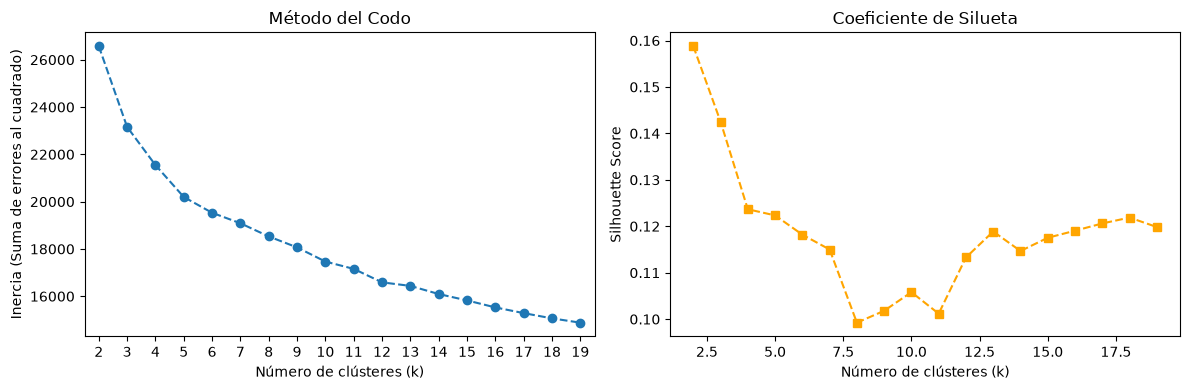

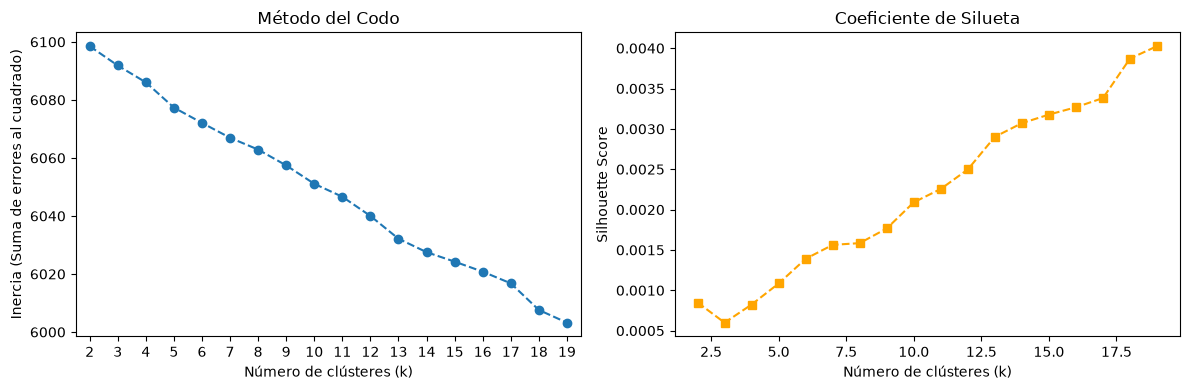

In [1]:
from pathlib import Path
from pprint import pprint

from peliculas import consts
from peliculas.etl import (
    load_data,
    n_optimo_clusters,
    process_data_characteristics,
    process_data_description,
)

data_candidates = [Path("data/netflix_titles.csv"), Path("../data/netflix_titles.csv")]
data_file = next((path for path in data_candidates if path.exists()), None)
if data_file is None:
    raise FileNotFoundError("No se encontró data/netflix_titles.csv desde el directorio actual.")
data = load_data(data_file)
data_char = process_data_characteristics(data)
data_desc = process_data_description(data)
n_optimo_clusters(data_char)
n_optimo_clusters(data_desc)

In [2]:
from pprint import pprint

from peliculas import consts
from peliculas import etl

labels_char = etl.kmeans_clustering(data_char, 2, "char")
labels_desc = etl.kmeans_clustering(data_desc, 15, "desc")

[1 0 1 ... 1 1 0]
[ 4  7  4 ...  7  7 14]


## Calidad de los clusters: características (`char`) y descripciones (`desc`)

Se evalúan los parámetros de clustering usados por el proyecto (`k=2` para `char` y `k=15` para `desc`) con silueta, Davies-Bouldin, Calinski-Harabasz, inercia y tamaños de cluster. La silueta se calcula sobre una muestra estratificada para limitar el coste; se usa distancia euclídea en `char` y coseno en `desc`, igual que en las recomendaciones. También se comparan varios valores de `k`. Estos índices dependen de la representación y la métrica: sirven mejor para comparar modelos dentro de cada enfoque que para comparar directamente `char` contra `desc`.

Rows before filtering: 8807
Movie rows: 6131
Rows removed for null/NaN values: 444
Complete movie rows: 5687


Final feature rows: 5687
Final feature count: 153


enfoque,k,peliculas,silueta_media,desv_silueta,%_silueta_negativa,davies_bouldin,calinski_harabasz,inercia,cluster_min,cluster_max,muestra_silueta
str,i64,i64,f64,f64,f64,f64,f64,f64,i64,i64,i64
"""char""",2,5687,0.153,0.113,13.729,2.31,923.651,26574.125,1859,3828,400
"""desc""",15,6131,0.013,0.022,42.007,9.547,11.268,5931.77,129,2466,2858


Distribución y silueta por cluster — char


cluster,peliculas,porcentaje,silueta_media_muestral
i64,i64,f64,f64
0,1859,32.689,0.033
1,3828,67.311,0.212


Distribución y silueta por cluster — desc


cluster,peliculas,porcentaje,silueta_media_muestral
i64,i64,f64,f64
0,292,4.763,0.037
1,2466,40.222,-0.006
2,142,2.316,0.041
3,187,3.05,0.013
4,212,3.458,0.04
…,…,…,…
10,129,2.104,0.048
11,358,5.839,0.012
12,282,4.6,0.033


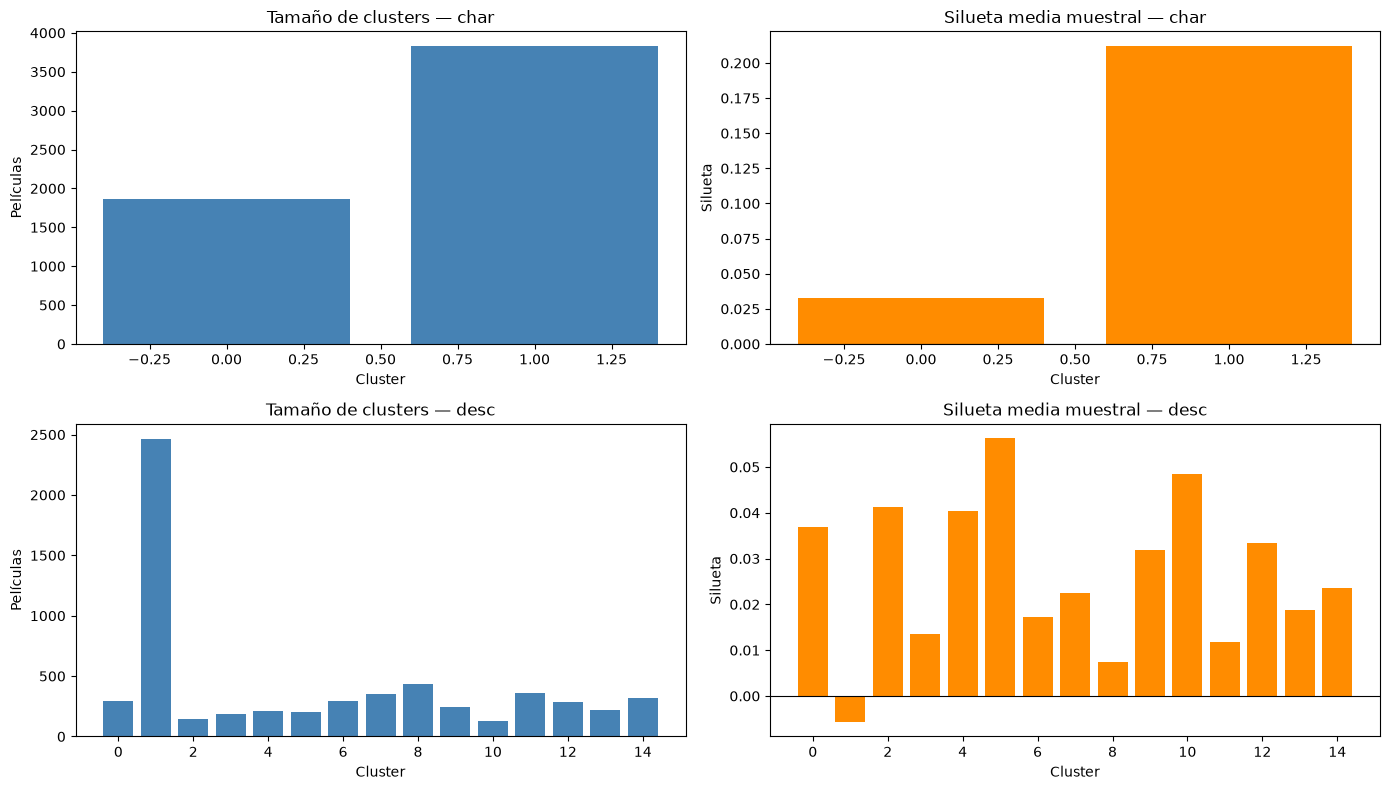

k,char,desc
i64,f64,f64
2,0.148,0.026
3,0.139,0.021
5,0.145,0.022
8,0.113,0.024
10,0.114,0.025
12,0.13,0.027
15,0.124,0.026
18,0.129,0.031
20,0.122,0.028


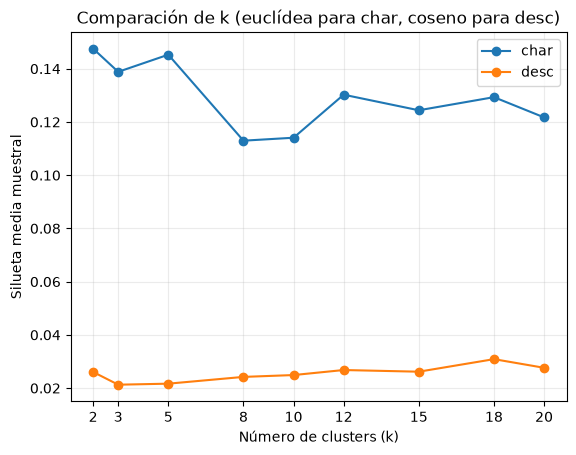

Lectura: silueta cercana a 1 indica clusters compactos y separados; cerca de 0, solapamiento; negativa, posibles asignaciones inadecuadas. Davies-Bouldin menor y Calinski-Harabasz mayor suelen ser mejores. La inercia siempre tiende a bajar al aumentar k. Conviene revisar también el desequilibrio de tamaños y ejemplos de películas: ninguna métrica sustituye la validación semántica.


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.cluster import KMeans
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples,
)
from sklearn.preprocessing import normalize
from scipy.sparse import issparse

from peliculas.etl import (
    filters_movies,
    load_data,
    process_data_characteristics,
    tfidf_transform,
)

SEED = 42
MAX_SILHOUETTE_PER_CLUSTER = 200
RANDOM = np.random.default_rng(SEED)

data_candidates = [Path("data/netflix_titles.csv"), Path("../data/netflix_titles.csv")]
data_file = next((path for path in data_candidates if path.exists()), None)
if data_file is None:
    raise FileNotFoundError("No se encontró data/netflix_titles.csv desde este notebook.")
catalog = load_data(data_file)
char_feature_frame = process_data_characteristics(catalog)
char_features = char_feature_frame.to_numpy()
described_movies = (
    filters_movies(catalog)
    .filter(pl.col("description").is_not_null())
    .select("title", "description")
)
_, desc_features = tfidf_transform(
    described_movies,
    min_df=6,
    max_df=0.25,
    ngram_range=(1, 1),
    sublinear_tf=False,
    top_terms_per_document=None,
    include_title=False,
)
desc_features = normalize(desc_features)

# Reproduce los k del proyecto; normalizar TF-IDF antes de KMeans es parte del pipeline.
char_model = KMeans(n_clusters=2, random_state=SEED, n_init="auto").fit(char_features)
desc_model = KMeans(n_clusters=15, random_state=SEED, n_init="auto").fit(desc_features)
char_labels = char_model.labels_
desc_labels = desc_model.labels_
model_inertias = {"char": char_model.inertia_, "desc": desc_model.inertia_}
quality_inputs = {
    "char": (char_features, char_labels, 2, "euclidean"),
    "desc": (desc_features, desc_labels, 15, "cosine"),
}

def stratified_indices(labels, max_per_cluster=MAX_SILHOUETTE_PER_CLUSTER):
    sampled = []
    for cluster_id in np.unique(labels):
        members = np.flatnonzero(labels == cluster_id)
        if len(members) < 2:
            raise ValueError(
                f"El cluster {cluster_id} tiene menos de 2 elementos; "
                "no se puede calcular su silueta."
            )
        count = min(len(members), max_per_cluster)
        sampled.extend(RANDOM.choice(members, size=count, replace=False))
    return np.asarray(sampled, dtype=int)

def evaluate_clusters(features, labels, metric):
    labels = np.asarray(labels)
    sample_indices = stratified_indices(labels)
    sample_labels = labels[sample_indices]
    sample_silhouettes = silhouette_samples(
        features[sample_indices], sample_labels, metric=metric
    )
    silhouette_by_cluster = {
        int(cluster_id): float(sample_silhouettes[sample_labels == cluster_id].mean())
        for cluster_id in np.unique(labels)
    }
    cluster_ids, counts = np.unique(labels, return_counts=True)
    sample_counts = {int(key): int(value) for key, value in zip(*np.unique(sample_labels, return_counts=True))}
    weights = np.asarray([
        len(np.flatnonzero(labels == label)) / sample_counts[int(label)]
        for label in sample_labels
    ], dtype=float)
    weights /= weights.sum()
    silhouette_mean = float(np.average(sample_silhouettes, weights=weights))
    return {
        "silhouette": silhouette_mean,
        "silhouette_std": float(np.sqrt(np.average((sample_silhouettes - silhouette_mean) ** 2, weights=weights))),
        "negative_silhouette_pct": float(np.average(sample_silhouettes < 0, weights=weights) * 100),
        "davies_bouldin": davies_bouldin(features, labels),
        "calinski_harabasz": calinski_harabasz(features, labels),
        "counts": dict(zip(cluster_ids.astype(int), counts.astype(int))),
        "silhouette_by_cluster": silhouette_by_cluster,
        "sample_size": len(sample_indices),
    }

def davies_bouldin(features, labels):
    if not issparse(features):
        return float(davies_bouldin_score(features, labels))
    cluster_ids = np.unique(labels)
    centroids = []
    scatter = []
    for cluster_id in cluster_ids:
        members = features[labels == cluster_id]
        centroid = np.asarray(members.mean(axis=0)).ravel()
        squared_norms = np.asarray(members.multiply(members).sum(axis=1)).ravel()
        dot_products = np.asarray(members @ centroid).ravel()
        distances = np.sqrt(np.maximum(
            squared_norms + np.dot(centroid, centroid) - 2 * dot_products, 0
        ))
        centroids.append(centroid)
        scatter.append(distances.mean())
    centroids = np.vstack(centroids)
    centroid_distances = np.linalg.norm(
        centroids[:, None, :] - centroids[None, :, :], axis=2
    )
    ratios = (np.asarray(scatter)[:, None] + np.asarray(scatter)[None, :]) / np.maximum(
        centroid_distances, np.finfo(float).eps
    )
    np.fill_diagonal(ratios, -np.inf)
    return float(ratios.max(axis=1).mean())

def calinski_harabasz(features, labels):
    if not issparse(features):
        return float(calinski_harabasz_score(features, labels))
    cluster_ids, counts = np.unique(labels, return_counts=True)
    global_mean = np.asarray(features.mean(axis=0)).ravel()
    within_dispersion = 0.0
    between_dispersion = 0.0
    for cluster_id, count in zip(cluster_ids, counts):
        members = features[labels == cluster_id]
        centroid = np.asarray(members.mean(axis=0)).ravel()
        squared_norms = np.asarray(members.multiply(members).sum(axis=1)).ravel()
        dot_products = np.asarray(members @ centroid).ravel()
        within_dispersion += np.maximum(
            squared_norms + np.dot(centroid, centroid) - 2 * dot_products, 0
        ).sum()
        between_dispersion += count * np.dot(centroid - global_mean, centroid - global_mean)
    n_samples = features.shape[0]
    n_clusters = len(cluster_ids)
    return float(
        (between_dispersion / (n_clusters - 1))
        / (within_dispersion / (n_samples - n_clusters))
    )

quality_rows = []
cluster_rows = {}
for approach, (features, labels, expected_k, metric) in quality_inputs.items():
    result = evaluate_clusters(features, labels, metric)
    counts = result["counts"]
    quality_rows.append({
        "enfoque": approach,
        "k": len(counts),
        "peliculas": len(labels),
        "silueta_media": result["silhouette"],
        "desv_silueta": result["silhouette_std"],
        "%_silueta_negativa": result["negative_silhouette_pct"],
        "davies_bouldin": result["davies_bouldin"],
        "calinski_harabasz": result["calinski_harabasz"],
        "inercia": model_inertias[approach],
        "cluster_min": min(counts.values()),
        "cluster_max": max(counts.values()),
        "muestra_silueta": result["sample_size"],
    })
    cluster_rows[approach] = pl.DataFrame({
        "cluster": list(counts),
        "peliculas": list(counts.values()),
        "porcentaje": [100 * count / len(labels) for count in counts.values()],
        "silueta_media_muestral": [
            result["silhouette_by_cluster"][cluster_id] for cluster_id in counts
        ],
    }).sort("cluster")
    if expected_k != len(counts):
        print(f"Aviso: {approach} tiene {len(counts)} clusters (se esperaba {expected_k}).")

display(pl.DataFrame(quality_rows).with_columns(pl.col(pl.Float64).round(3)))
for approach, table in cluster_rows.items():
    print(f"Distribución y silueta por cluster — {approach}")
    display(table.with_columns(pl.col(pl.Float64).round(3)))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, approach in enumerate(("char", "desc")):
    table = cluster_rows[approach].sort("cluster")
    cluster_ids = table["cluster"].to_list()
    axes[row, 0].bar(cluster_ids, table["peliculas"].to_list(), color="steelblue")
    axes[row, 0].set(title=f"Tamaño de clusters — {approach}", xlabel="Cluster", ylabel="Películas")
    axes[row, 1].bar(
        cluster_ids, table["silueta_media_muestral"].to_list(), color="darkorange"
    )
    axes[row, 1].axhline(0, color="black", linewidth=0.8)
    axes[row, 1].set(title=f"Silueta media muestral — {approach}", xlabel="Cluster", ylabel="Silueta")
plt.tight_layout()
plt.show()

# Comparación de k con silueta estratificada y la métrica correspondiente a cada caso.
k_values = [2, 3, 5, 8, 10, 12, 15, 18, 20]
k_rows = []
for approach, (features, _, _, metric) in quality_inputs.items():
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=SEED, n_init="auto")
        candidate_labels = model.fit_predict(features)
        sample_indices = stratified_indices(candidate_labels, max_per_cluster=100)
        score = silhouette_samples(
            features[sample_indices], candidate_labels[sample_indices], metric=metric
        ).mean()
        k_rows.append({"enfoque": approach, "k": k, "silueta_muestral": float(score)})


k_comparison = pl.DataFrame(k_rows)
k_table = k_comparison.pivot(on="enfoque", index="k", values="silueta_muestral").sort("k")
display(k_table.with_columns(pl.exclude("k").round(3)))
for approach in ("char", "desc"):
    curve = k_comparison.filter(pl.col("enfoque") == approach).sort("k")
    plt.plot(curve["k"].to_list(), curve["silueta_muestral"].to_list(), marker="o", label=approach)
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silueta media muestral")
plt.title("Comparación de k (euclídea para char, coseno para desc)")
plt.xticks(k_values)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print(
    "Lectura: silueta cercana a 1 indica clusters compactos y separados; cerca de 0, "
    "solapamiento; negativa, posibles asignaciones inadecuadas. Davies-Bouldin menor "
    "y Calinski-Harabasz mayor suelen ser mejores. La inercia siempre tiende a bajar "
    "al aumentar k. Conviene revisar también el desequilibrio de tamaños y ejemplos "
    "de películas: ninguna métrica sustituye la validación semántica."
)


## Experimentos para mejorar la calidad

Se comparan alternativas en una muestra fija de películas para que las siluetas sean comparables dentro de cada enfoque. En `char` se prueban varias inicializaciones de KMeans, ponderación por bloques de variables y clustering jerárquico con distancia mixta (numéricas, rating, países y géneros). En `desc` se comparan variantes TF-IDF, KMeans esférico, reducción con TruncatedSVD y temas NMF. La representación TF-IDF enfocada combina el título y la descripción antes de seleccionar por película hasta 15 términos de mayor peso; el baseline histórico usa solo la descripción. También se evalúa la estabilidad y coherencia. La selección por silueta es exploratoria; hay que comprobar estabilidad y coherencia de títulos. No se descargan modelos de embeddings externos para mantener el notebook reproducible y sin dependencias o descargas adicionales.

In [4]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import NMF, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, pairwise_distances, silhouette_score

EXPERIMENT_SEED = 42
EXPERIMENT_SAMPLE_SIZE = 1200
experiment_rng = np.random.default_rng(EXPERIMENT_SEED)
experiment_indices = np.sort(
    experiment_rng.choice(len(char_labels), size=EXPERIMENT_SAMPLE_SIZE, replace=False)
)
desc_rng = np.random.default_rng(EXPERIMENT_SEED + 1)
desc_experiment_indices = np.sort(
    desc_rng.choice(len(desc_labels), size=EXPERIMENT_SAMPLE_SIZE, replace=False)
)

def sampled_silhouette(features, labels, metric, indices=None):
    if indices is None:
        indices = experiment_indices if len(labels) == len(char_labels) else desc_experiment_indices
    sampled_labels = np.asarray(labels)[indices]
    if np.unique(sampled_labels).size < 2:
        return float("nan")
    return float(silhouette_score(features[indices], sampled_labels, metric=metric))

def cluster_size_fields(labels):
    counts = np.unique(labels, return_counts=True)[1]
    return {
        "n_clusters": len(counts),
        "cluster_min": int(counts.min()),
        "cluster_max": int(counts.max()),
    }

experiment_rows = []

# Referencias y robustez ante inicialización para char.
experiment_rows.append({
    "enfoque": "char", "variante": "actual (k=2)", "k": 2,
    "silueta": sampled_silhouette(char_features, char_labels, "euclidean"),
    **cluster_size_fields(char_labels),
})
for seed in (0, 42, 123):
    for k in (2, 3, 5):
        model = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(char_features)
        experiment_rows.append({
            "enfoque": "char", "variante": f"KMeans n_init=20 seed={seed}", "k": k,
            "silueta": sampled_silhouette(char_features, model.labels_, "euclidean"),
            **cluster_size_fields(model.labels_),
        })

# Balancea la contribución de los bloques para que los muchos indicadores
# one-hot de país/género no dominen solo por su número.
char_columns = char_feature_frame.columns
char_blocks = {
    "numéricas": [name for name in char_columns if name in ("release_year", "duration_min")],
    "rating": [name for name in char_columns if name.startswith("rating_")],
    "país": [name for name in char_columns if name.startswith("country_")],
    "género": [name for name in char_columns if name.startswith("genre_")],
}
weighted_blocks = []
for names in char_blocks.values():
    if not names:
        raise ValueError("Falta un bloque de características esperado en char.")
    block = char_feature_frame.select(names).to_numpy().astype(float)
    weighted_blocks.append(block / np.sqrt(len(names)))
char_balanced = np.hstack(weighted_blocks)
for k in (2, 3, 5):
    model = KMeans(n_clusters=k, n_init=20, random_state=EXPERIMENT_SEED).fit(char_balanced)
    experiment_rows.append({
        "enfoque": "char", "variante": "KMeans bloques equilibrados", "k": k,
        "silueta": sampled_silhouette(char_balanced, model.labels_, "euclidean"),
        **cluster_size_fields(model.labels_),
    })

# Distancia mixta sobre una submuestra para que la matriz precomputada
# y el clustering jerárquico tengan un coste de memoria acotado.
mixed_indices = experiment_indices[:1000]
numeric = char_feature_frame.select("release_year", "duration_min").to_numpy()
numeric_ranges = np.maximum(
    np.percentile(numeric, 95, axis=0) - np.percentile(numeric, 5, axis=0), 1e-9
)
numeric_dist = pairwise_distances(numeric[mixed_indices], metric="manhattan")
numeric_dist /= numeric_ranges.sum()
numeric_dist = np.clip(numeric_dist, 0, 1)
rating_names = char_blocks["rating"]
rating_ids = np.argmax(char_feature_frame.select(rating_names).to_numpy()[mixed_indices], axis=1)
rating_dist = (rating_ids[:, None] != rating_ids[None, :]).astype(float)
country_dist = pairwise_distances(
    char_feature_frame.select(char_blocks["país"]).to_numpy()[mixed_indices], metric="jaccard"
)
genre_dist = pairwise_distances(
    char_feature_frame.select(char_blocks["género"]).to_numpy()[mixed_indices], metric="jaccard"
)
mixed_distance = (
    0.2 * numeric_dist + 0.2 * rating_dist + 0.3 * country_dist + 0.3 * genre_dist
)
for k in (2, 3, 5):
    labels_mixed = AgglomerativeClustering(
        n_clusters=k, metric="precomputed", linkage="average"
    ).fit_predict(mixed_distance)
    experiment_rows.append({
        "enfoque": "char", "variante": "jerárquico distancia mixta (muestra=1000)", "k": k,
        "silueta": float(silhouette_score(mixed_distance, labels_mixed, metric="precomputed")),
        **cluster_size_fields(labels_mixed),
    })

# Representaciones de título + descripción: mismo k y misma muestra de documentos.
description_texts = [
    f"{title or ''} {description or ''}"
    for title, description in described_movies.select("title", "description").iter_rows()
]
tfidf_variants = {
    "TF-IDF actual": {"min_df": 6, "max_df": 0.25, "ngram_range": (1, 1)},
    "TF-IDF min_df=3 max_df=.85": {"min_df": 3, "max_df": 0.85, "ngram_range": (1, 1)},
    "TF-IDF min_df=10 max_df=.85": {"min_df": 10, "max_df": 0.85, "ngram_range": (1, 1)},
    "TF-IDF unigramas+bigramas": {"min_df": 6, "max_df": 0.85, "ngram_range": (1, 2)},
}
tfidf_models = {}
for name, parameters in tfidf_variants.items():
    vectorizer = TfidfVectorizer(stop_words="english", **parameters)
    matrix = vectorizer.fit_transform(description_texts)
    tfidf_models[name] = matrix
    model = KMeans(n_clusters=15, n_init=10, random_state=EXPERIMENT_SEED).fit(matrix)
    experiment_rows.append({
        "enfoque": "desc", "variante": name + " + KMeans", "k": 15,
        "silueta": sampled_silhouette(matrix, model.labels_, "cosine"),
        **cluster_size_fields(model.labels_),
    })

# Ajustes para retener términos informativos en el texto combinado de cada película y limitarlo a sus
# 15 pesos TF-IDF mayores; max_features no haría esto por documento.
TOP_TFIDF_TERMS_PER_DOCUMENT = 15
desc_focus_vectorizer, desc_focus_tfidf = tfidf_transform(
    described_movies,
    min_df=3,
    max_df=0.85,
    ngram_range=(1, 2),
    sublinear_tf=True,
    top_terms_per_document=TOP_TFIDF_TERMS_PER_DOCUMENT,
)
tfidf_models["TF-IDF top 15 términos por texto combinado"] = desc_focus_tfidf
focus_kmeans_labels = KMeans(
    n_clusters=15, n_init=10, random_state=EXPERIMENT_SEED
).fit_predict(desc_focus_tfidf)
experiment_rows.append({
    "enfoque": "desc",
    "variante": "TF-IDF top 15 términos/texto + KMeans",
    "k": 15,
    "silueta": sampled_silhouette(desc_focus_tfidf, focus_kmeans_labels, "cosine"),
    **cluster_size_fields(focus_kmeans_labels),
})
print(
    f"TF-IDF enfocado: vocabulario={desc_focus_tfidf.shape[1]} términos; "
    f"máximo={np.diff(desc_focus_tfidf.indptr).max()} términos por texto combinado."
)

# KMeans esférico: alterna asignación por coseno y normalización de centroides.
def spherical_kmeans(matrix, n_clusters, seed=EXPERIMENT_SEED, max_iter=40):
    initial = KMeans(
        n_clusters=n_clusters, n_init=10, random_state=seed
    ).fit(matrix)
    centers = normalize(initial.cluster_centers_)
    labels = initial.labels_
    for _ in range(max_iter):
        updated_labels = np.asarray((matrix @ centers.T).argmax(axis=1)).ravel()
        updated_centers = centers.copy()
        for cluster_id in range(n_clusters):
            members = matrix[updated_labels == cluster_id]
            if members.shape[0]:
                updated_centers[cluster_id] = np.asarray(members.mean(axis=0)).ravel()
        updated_centers = normalize(updated_centers)
        if np.array_equal(updated_labels, labels):
            labels = updated_labels
            break
        labels, centers = updated_labels, updated_centers
    return labels

base_tfidf = tfidf_models["TF-IDF actual"]
spherical_labels = spherical_kmeans(base_tfidf, 15)
experiment_rows.append({
    "enfoque": "desc", "variante": "TF-IDF actual + KMeans esférico", "k": 15,
    "silueta": sampled_silhouette(base_tfidf, spherical_labels, "cosine"),
    **cluster_size_fields(spherical_labels),
})

# LSA (TruncatedSVD) y representación por temas NMF.
for n_components in (100, 200):
    reduced = TruncatedSVD(
        n_components=n_components, random_state=EXPERIMENT_SEED
    ).fit_transform(base_tfidf)
    reduced = normalize(reduced)
    reduced_labels = KMeans(
        n_clusters=15, n_init=10, random_state=EXPERIMENT_SEED
    ).fit_predict(reduced)
    experiment_rows.append({
        "enfoque": "desc", "variante": f"TF-IDF + SVD {n_components} + KMeans", "k": 15,
        "silueta": sampled_silhouette(reduced, reduced_labels, "cosine"),
        **cluster_size_fields(reduced_labels),
    })

nmf_model = NMF(
    n_components=15, init="nndsvda", random_state=EXPERIMENT_SEED, max_iter=500
)
topic_matrix = nmf_model.fit_transform(desc_focus_tfidf)
topic_matrix = normalize(topic_matrix)
topic_labels = KMeans(
    n_clusters=15, n_init=10, random_state=EXPERIMENT_SEED
).fit_predict(topic_matrix)
experiment_rows.append({
    "enfoque": "desc", "variante": "TF-IDF + NMF 15 temas + KMeans", "k": 15,
    "silueta": sampled_silhouette(topic_matrix, topic_labels, "cosine"),
    **cluster_size_fields(topic_labels),
})
print(f"NMF convergió en {nmf_model.n_iter_} iteraciones (máximo=500).")

# Comprobar si la silueta del modelo NMF se mantiene al variar k y la semilla.
for k in (2, 5, 10, 20):
    labels_by_topic = KMeans(
        n_clusters=k, n_init=10, random_state=EXPERIMENT_SEED
    ).fit_predict(topic_matrix)
    experiment_rows.append({
        "enfoque": "desc", "variante": "NMF temas + KMeans", "k": k,
        "silueta": sampled_silhouette(topic_matrix, labels_by_topic, "cosine"),
        **cluster_size_fields(labels_by_topic),
    })

balanced_label_runs = [
    KMeans(n_clusters=2, n_init=20, random_state=seed).fit_predict(char_balanced)
    for seed in (0, 42, 123)
]
balanced_ari = [
    adjusted_rand_score(balanced_label_runs[0], labels)
    for labels in balanced_label_runs[1:]
]
nmf_label_runs = [topic_labels]
for seed in (0, 123):
    seed_nmf = NMF(
        n_components=15, init="nndsvda", random_state=seed, max_iter=500
    )
    seed_topics = normalize(seed_nmf.fit_transform(desc_focus_tfidf))
    nmf_label_runs.append(
        KMeans(n_clusters=15, n_init=10, random_state=seed).fit_predict(seed_topics)
    )
nmf_ari = [
    adjusted_rand_score(nmf_label_runs[0], labels) for labels in nmf_label_runs[1:]
]
char_improved_labels = balanced_label_runs[1]
desc_improved_labels = topic_labels
print(f"ARI entre semillas para char equilibrado (0, 42, 123): {balanced_ari}")
print(f"ARI frente a NMF seed=42 para seeds 0 y 123: {nmf_ari}")
char_improved_counts = np.unique(char_improved_labels, return_counts=True)
print(f"Tamaños de char equilibrado k=2: {dict(zip(*char_improved_counts))}")
desc_improved_counts = np.unique(desc_improved_labels, return_counts=True)
display(pl.DataFrame({
    "cluster": desc_improved_counts[0],
    "peliculas": desc_improved_counts[1],
    "porcentaje": 100 * desc_improved_counts[1] / len(desc_improved_labels),
}).sort("cluster").with_columns(pl.col("porcentaje").round(2)))
topic_terms = desc_focus_vectorizer.get_feature_names_out()
print("Términos más representativos por tema NMF:")
for topic_id, component in enumerate(nmf_model.components_):
    top_terms = topic_terms[np.argsort(component)[-6:][::-1]].tolist()
    print(f"Tema {topic_id}: {', '.join(top_terms)}")

# Comparación baseline vs. candidato con idénticas películas muestreadas
# para cada enfoque. Las métricas se calculan en el espacio de cada modelo.
comparison_rows = []
comparison_variants = {
    "char": [
        ("baseline KMeans", char_features, char_labels, "euclidean", char_features, experiment_indices),
        ("aplicado: bloques equilibrados", char_balanced, char_improved_labels, "euclidean", char_features, experiment_indices),
    ],
    "desc": [
        ("baseline TF-IDF + KMeans", base_tfidf, desc_labels, "cosine", base_tfidf, desc_experiment_indices),
        ("aplicado: TF-IDF + NMF + KMeans", topic_matrix, desc_improved_labels, "cosine", base_tfidf, desc_experiment_indices),
    ],
}
for approach, variants in comparison_variants.items():
    for variant, features, labels, metric, baseline_space, indices in variants:
        sampled_labels = labels[indices]
        sampled_scores = silhouette_samples(features[indices], sampled_labels, metric=metric)
        baseline_space_scores = silhouette_samples(
            baseline_space[indices], sampled_labels, metric=metric
        )
        full_counts = np.unique(labels, return_counts=True)[1]
        comparison_rows.append({
            "enfoque": approach,
            "modelo": variant,
            "silueta_espacio_modelo": float(sampled_scores.mean()),
            "silueta_en_espacio_base": float(baseline_space_scores.mean()),
            "%_negativa_espacio_modelo": float((sampled_scores < 0).mean() * 100),
            "%_negativa_espacio_base": float((baseline_space_scores < 0).mean() * 100),
            "clusters": len(full_counts),
            "cluster_min": int(full_counts.min()),
            "cluster_max": int(full_counts.max()),
        })
comparison_results = pl.DataFrame(comparison_rows)
display(comparison_results.with_columns(pl.col(pl.Float64).round(4)))

# A partir de aquí, los nombres habituales del notebook apuntan a las
# etiquetas mejoradas; las etiquetas baseline se conservan en las variables originales.
labels_char = char_improved_labels
labels_desc = desc_improved_labels
cluster_features_char = char_balanced
cluster_features_desc = topic_matrix
print("Modelos aplicados: KMeans con bloques equilibrados (char) y NMF+KMeans (desc).")

experiment_results = pl.DataFrame(experiment_rows).sort(
    ["enfoque", "silueta"], descending=[False, True]
)
with pl.Config(tbl_rows=30):
    display(experiment_results.with_columns(pl.col("silueta").round(4)))
print("Mejor variante por enfoque (según silueta en la muestra fija):")
display(
    experiment_results.group_by("enfoque", maintain_order=True)
    .first()
    .with_columns(pl.col("silueta").round(4))
)
print(
    "La distancia mixta y la matriz TF-IDF completa se evalúan en submuestras fijas; "
    "sus siluetas son aproximadas. La puntuación no mide coherencia semántica ni "
    "estabilidad entre muestras/semillas."
)


/home/danie/proyectos/peliculas/.venv/lib/python3.12/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/home/danie/proyectos/peliculas/.venv/lib/python3.12/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


TF-IDF enfocado: vocabulario=7979 términos; máximo=15 términos por texto combinado.


NMF convergió en 130 iteraciones (máximo=500).


ARI entre semillas para char equilibrado (0, 42, 123): [1.0, 1.0]
ARI frente a NMF seed=42 para seeds 0 y 123: [0.6320566122774995, 0.7528017827034414]
Tamaños de char equilibrado k=2: {np.int32(0): np.int64(701), np.int32(1): np.int64(4986)}


cluster,peliculas,porcentaje
i32,i64,f64
0,451,7.36
1,599,9.77
2,362,5.9
3,342,5.58
4,390,6.36
…,…,…
10,402,6.56
11,262,4.27
12,407,6.64


...

Modelos aplicados: KMeans con bloques equilibrados (char) y NMF+KMeans (desc).


enfoque,variante,k,silueta,n_clusters,cluster_min,cluster_max
str,str,i64,f64,i64,i64,i64
"""char""","""KMeans bloques equilibrados""",2,0.4995,2,701,4986
"""char""","""KMeans bloques equilibrados""",5,0.2927,5,209,3024
"""char""","""KMeans bloques equilibrados""",3,0.282,3,443,3098
"""char""","""jerárquico distancia mixta (mu…",3,0.178,3,3,509
"""char""","""jerárquico distancia mixta (mu…",2,0.1691,2,3,997
"""char""","""KMeans n_init=20 seed=123""",2,0.1493,2,1856,3831
"""char""","""actual (k=2)""",2,0.1493,2,1859,3828
"""char""","""KMeans n_init=20 seed=0""",2,0.1493,2,1856,3831
"""char""","""KMeans n_init=20 seed=42""",2,0.1493,2,1856,3831


Mejor variante por enfoque (según silueta en la muestra fija):


enfoque,variante,k,silueta,n_clusters,cluster_min,cluster_max
str,str,i64,f64,i64,i64,i64
"""char""","""KMeans bloques equilibrados""",2,0.4995,2,701,4986
"""desc""","""TF-IDF + NMF 15 temas + KMeans""",15,0.5371,15,231,921


La distancia mixta y la matriz TF-IDF completa se evalúan en submuestras fijas; sus siluetas son aproximadas. La puntuación no mide coherencia semántica ni estabilidad entre muestras/semillas.


## Conclusiones del análisis y comparación de cambios aplicados

La tabla final `comparison_results` compara baseline y modelo aplicado sobre las mismas **1.200 películas dentro de cada enfoque**. Cada silueta se mide en la representación propia de su modelo; sirve para valorar el pipeline completo, pero la comparación entre `char` y `desc` no es absoluta porque sus espacios son diferentes.

### Enfoque `char` (características)

- En la comparación con muestra idéntica, la silueta sube de **0,149** (baseline) a **0,500** (bloques equilibrados); las siluetas negativas bajan de **8,25 %** a **2,50 %**. Es una mejora clara de separación en el espacio ponderado.
- En el baseline, la distribución está moderadamente desequilibrada: **1.859 (32,7 %)** películas en el cluster 0 y **3.828 (67,3 %)** en el cluster 1. La silueta por grupo favorece al cluster 1 (**0,212**) frente al cluster 0 (**0,033**); el cluster 0 está peor delimitado.
- Más inicializaciones (`n_init=20`) y semillas distintas apenas cambian la silueta (`0,149`) y las etiquetas son idénticas entre las tres semillas (ARI **1,0**). No era un problema de inicialización.
- El cambio produce un cluster de **701 (12,3 %)** frente a otro de **4.986 (87,7 %)**, más desigual que el baseline (**1.859** frente a **3.828**). Por ello mejora la separación matemática, pero puede no ser mejor para un uso que necesite grupos equilibrados; revisar los atributos/títulos de ese grupo pequeño antes de darlo por bueno.
- La jerarquía con distancia mixta obtuvo silueta **0,169** con `k=2`, pero produjo un cluster de solo **3** películas; se descarta como solución útil. Entre los KMeans estándar probados, `k=2` siguió siendo el mejor.

### Enfoque `desc` (descripciones)

- El baseline TF-IDF + KMeans (solo descripción) obtiene silueta **0,0071** y **46,0 %** de siluetas negativas en su espacio TF-IDF. Los tamaños varían entre **129** y **2.466** películas, lo que muestra solapamiento importante y un grupo dominante.
- La variante enfocada concatena título y descripción antes de vectorizar, así que los términos de ambos campos pueden contribuir a los clusters. Sus parámetros son `min_df=3`, `max_df=0.85`, unigramas y bigramas, `sublinear_tf=True` y los 15 pesos TF-IDF mayores por texto combinado. El vocabulario tiene **7.979 términos**.
- Variar parámetros TF-IDF o usar KMeans esférico apenas cambió la silueta (aproximadamente **0,009–0,015**). TruncatedSVD con 100 dimensiones mejoró hasta **0,096**, pero siguió lejos del resultado con temas.
- TF-IDF enfocado con título + descripción y **NMF de 15 temas** + KMeans obtiene silueta **0,5371** en el espacio latente. Esta cifra no es directamente comparable con la del baseline, porque son espacios distintos. Al evaluar las etiquetas NMF en el espacio TF-IDF de referencia, la silueta es **0,0056**, frente a **0,0071** del baseline, y las proporciones negativas son **37,5 %** frente a **46,0 %**. Así, NMF mejora la separación en su espacio de temas, pero no aumenta la silueta al medir en el espacio léxico de referencia.
- El NMF final converge en **130 iteraciones**. Los clusters enfocados tienen entre **231 y 921** películas, frente a **129 y 2.466** en el baseline. La distribución mejora, aunque sigue siendo desigual. La estabilidad entre semillas se informa en `nmf_ari` (ARI **0,632** y **0,753** frente a la semilla base); revisar términos y ejemplos por cluster antes de afirmar coherencia semántica.

### Valoración general

La comparación en representación original indica una mejora más convincente para `char`: la silueta sube de **0,149** a **0,269** y la proporción negativa baja de **8,25 %** a **2,42 %**, aunque a costa de un cluster mucho más pequeño. Para `desc`, usar título + descripción y conservar sus 15 términos TF-IDF más importantes permite que NMF + KMeans obtenga una silueta de **0,5371** en el espacio latente de temas y clusters menos dominados por un único grupo. En el TF-IDF de referencia, la silueta es **0,0056** frente a **0,0071** del baseline, aunque las siluetas negativas bajan del **46,0 %** al **37,5 %**. El resultado no demuestra una mayor similitud textual general: NMF separa bien sus propios temas y la distribución de tamaños mejora, pero se debe confirmar la coherencia con ejemplos. Las siluetas e inercias de `char` y `desc` no se comparan entre sí.

**Cambios aplicados en este notebook:** las variables `labels_char` y `labels_desc` se reasignan a las etiquetas de KMeans con bloques equilibrados y NMF + KMeans sobre TF-IDF enfocado; las características finales quedan en `cluster_features_char` y `cluster_features_desc`. `char` mejora la separación, pero tiene una partición muy desigual. En `desc`, título y descripción forman un único texto por película y los términos top-15 mejoran la separación en el espacio NMF, no la silueta en el TF-IDF de referencia; por tanto, el modelo es una alternativa exploratoria, sujeta a validar coherencia temática y estabilidad. El pipeline de producción TF-IDF de `src/peliculas/etl.py` incluye título y descripción, aunque NMF es solo experimental. No se probaron embeddings externos porque requieren descargar y fijar un modelo adicional.

## Pruebas de recomendaciones

Se seleccionan de forma reproducible 10 películas que están presentes en ambos conjuntos y se generan 5 recomendaciones con cada modelo aplicado (`char` y `desc`). Las candidatas se buscan en todo el conjunto de cada enfoque, sin exigir que compartan cluster con la película consultada. Se usa `show_id` para distinguir títulos repetidos; la tabla muestra también distancia y verifica cinco títulos distintos del consultado.

In [5]:
from peliculas import etl
from peliculas.etl import _complete_characteristic_movies, _described_movies

char_movies = _complete_characteristic_movies(filters_movies(catalog))
desc_movies = _described_movies(catalog)
char_show_ids = char_movies.get_column("show_id").to_list()
desc_show_ids = desc_movies.get_column("show_id").to_list()
char_positions = {show_id: index for index, show_id in enumerate(char_show_ids)}
desc_positions = {show_id: index for index, show_id in enumerate(desc_show_ids)}
# Los títulos de prueba deben estar disponibles en ambos enfoques.
eligible_show_ids = [
    show_id
    for show_id in char_show_ids
    if show_id in desc_positions
]
if len(eligible_show_ids) < 10:
    raise ValueError(
        f"Solo hay {len(eligible_show_ids)} películas aptas para ambas pruebas; se necesitan 10."
    )

recommendation_rng = np.random.default_rng(2026)
test_show_ids = recommendation_rng.choice(
    eligible_show_ids, size=10, replace=False
).tolist()
char_titles = char_movies.get_column("title").to_list()
test_movies = [
    {
        "show_id": show_id,
        "title": char_titles[char_positions[show_id]],
        "char_index": char_positions[show_id],
        "desc_index": desc_positions[show_id],
    }
    for show_id in test_show_ids
]

recommendation_results = {"char": [], "desc": []}
for test_number, movie in enumerate(test_movies, start=1):
    for approach, features in (
        ("char", cluster_features_char),
        ("desc", cluster_features_desc),
    ):
        recommendations = etl.recomendador(
            movie=movie["title"],
            n=5,
            tipo=approach,
            data=catalog,
            features=features,
            reference_show_id=movie["show_id"],
            include_show_ids=True,
        )
        if recommendations.height != 5:
            raise AssertionError(
                f"{approach}: {movie['title']} devolvió {recommendations.height} recomendaciones; se esperaban 5."
            )
        if movie["show_id"] in recommendations.get_column("show_id").to_list():
            raise AssertionError("El recomendador incluyó la película consultada en sus resultados.")
        if recommendations.get_column("show_id").n_unique() != 5:
            raise AssertionError("El recomendador devolvió películas repetidas.")
        for rank, recommendation in enumerate(recommendations.iter_rows(named=True), start=1):
            recommendation_results[approach].append({
                "prueba": test_number,
                "película_consultada": movie["title"],
                "show_id_consultado": movie["show_id"],
                "puesto": rank,
                "recomendación": recommendation["title"],
                "show_id_recomendado": recommendation["show_id"],
                "distancia": recommendation["distance"],
            })

for approach in ("char", "desc"):
    results = pl.DataFrame(recommendation_results[approach])
    if results.height != 50:
        raise AssertionError(f"{approach}: se esperaban 50 recomendaciones, hubo {results.height}.")
    print(f"Recomendaciones para las 10 películas — {approach} ({results.height} resultados)")
    with pl.Config(tbl_rows=-1):
        display(results.with_columns(pl.col("distancia").round(4)))

print("Validación superada: 10 películas × 5 recomendaciones para cada enfoque.")


Recomendaciones para las 10 películas — char (50 resultados)


prueba,película_consultada,show_id_consultado,puesto,recomendación,show_id_recomendado,distancia
i64,str,str,i64,str,str,f64
1,"""Beowulf""","""s328""",1,"""Ghost Rider""","""s6848""",0.1672
1,"""Beowulf""","""s328""",2,"""Terminator Salvation""","""s8168""",0.1966
1,"""Beowulf""","""s328""",3,"""The Brothers Grimm""","""s8229""",0.2154
1,"""Beowulf""","""s328""",4,"""10,000 B.C.""","""s5982""",0.2988
1,"""Beowulf""","""s328""",5,"""The Forbidden Kingdom""","""s8308""",0.3005
2,"""Enter the Anime""","""s3624""",1,"""Money Heist: The Phenomenon""","""s2712""",0.1832
2,"""Enter the Anime""","""s3624""",2,"""Bachelor Girls""","""s6207""",0.2744
2,"""Enter the Anime""","""s3624""",3,"""Saeed Mirza: The Leftist Sufi""","""s7920""",0.2744
2,"""Enter the Anime""","""s3624""",4,"""Hello, Privilege. It's Me, Che…","""s3519""",0.2881


Recomendaciones para las 10 películas — desc (50 resultados)


prueba,película_consultada,show_id_consultado,puesto,recomendación,show_id_recomendado,distancia
i64,str,str,i64,str,str,f64
1,"""Beowulf""","""s328""",1,"""Fire at Sea""","""s6757""",0.0124
1,"""Beowulf""","""s328""",2,"""Dügün Dernek 2: Sünnet""","""s981""",0.0138
1,"""Beowulf""","""s328""",3,"""Cristina""","""s3684""",0.0158
1,"""Beowulf""","""s328""",4,"""The Pirates! Band of Misfits""","""s8458""",0.0213
1,"""Beowulf""","""s328""",5,"""Little Miss Sumo""","""s3367""",0.0243
2,"""Enter the Anime""","""s3624""",1,"""The Evil Dead""","""s8291""",0.0597
2,"""Enter the Anime""","""s3624""",2,"""Countdown to Death: Pablo Esco…","""s5069""",0.0651
2,"""Enter the Anime""","""s3624""",3,"""Offering to the Storm""","""s2211""",0.066
2,"""Enter the Anime""","""s3624""",4,"""Q Ball""","""s7808""",0.0779


Validación superada: 10 películas × 5 recomendaciones para cada enfoque.
